# NTN RT Multi-Elevation Simulation

**Extends the single-building scenario to a complex urban XML scene.**

| Statistic | Description |
|---|---|
| **Rician K-Factor** | Ratio of LoS power to scattered power |
| **RMS Delay Spread** | Power-weighted std-dev of multipath delays |
| **LoS Probability** | Fraction of receiver positions with a visible LoS path |

**What's new vs. the single-building notebook:**
- Automatic receiver placement via Mitsuba ray-cast occupancy grid
- Multiple elevation angles (10, 30, 60, 80 deg) at 20 km slant distance
- Dual-GPU support: two elevation angles run in parallel, one per GPU
- All propagation parameters exposed at the top of the notebook
- Per-angle checkpointing and result merging
- Cross-angle comparison plots

## 1 - Environment Setup

In [1]:
import os, sys
# DrJIT / LLVM path
# NOTE: previously followed by `%env DRJIT_LIBLLVM_PATH="..."` -- removed.
# IPython's %env magic does not strip quotes from the value, so that line
# was setting os.environ['DRJIT_LIBLLVM_PATH'] to the literal string
# '"/usr/lib/x86_64-linux-gnu/libLLVM-20.so"' (quote characters included).
# Harmless for drjit in this kernel (already initialized on the line above,
# using the correct unquoted value) but fatal for any subprocess launched
# later (Section 6) that inherits this corrupted value via env=os.environ
# and tries to load DrJIT/LLVM fresh.
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit
# Add script directory to path so helper modules can be imported
SCRIPT_DIR = os.path.abspath(".")
sys.path.insert(0, SCRIPT_DIR)
print("Environment configured.")

Environment configured.


## 2 - Imports

In [2]:
import json
import time
import gc
import pickle
import subprocess
import math
import numpy as np
from scipy import constants
%matplotlib inline
import matplotlib.pyplot as plt
# Sionna / DrJIT
import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt
import mitsuba as mi
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies, LambertianPattern, DirectivePattern
# Local helpers
from channel_utils    import (rms_delay_spread, complex_channel,                                tx_position_from_elevation, elevation_summary)
from scene_utils      import (build_occupancy_grid, build_occupancy_grid_xml,
                               sample_rx_positions, build_scene_batch,
                               save_rx_positions, load_rx_positions)
from checkpoint_utils import (save_checkpoint, load_checkpoint, save_results,
                               load_results, load_all_results, simulation_status)
from plot_utils       import (plot_rx_positions, plot_occupancy_grid, plot_spatial_stats,
                               plot_los_map, plot_cdfs, plot_angle_comparison,
                               plot_cir, plot_metrics_vs_elevation_multi_config, print_summary)
from atmospheric_utils import (compute_atmospheric_effects,
                                apply_atmospheric_corrections,
                                atmospheric_deterministic_summary,
                                WEATHER_PRESETS, RAIN_PRESETS)
from ionospheric_utils import (sample_faraday_angle, apply_ionospheric_corrections,
                                ionospheric_summary, TEC_PRESETS)
from fetch_vtec        import fetch_vtec_stats, vtec_for_pipeline
from fetch_tle         import fetch_tle_catalog
from orbital_utils import (
        make_reference_satrec, find_pass,
        find_pass_with_geometry_class, REFERENCE_LEO_ALTITUDES_KM,
        generate_waypoints, parse_tle_catalog, parse_tle_text,
        search_tle_catalog_for_pass, best_pass_in_catalog,
    )
from sgp4.api import jday
print("All imports OK.")

All imports OK.


## 3 - Global Parameters

> **Update the values in this cell before running.**  
> Every simulation knob is exposed here.

In [3]:
# ─── SCENE ────────────────────────────────────────────────────────────────────
SCENE_XML       = "/path/to/wharf_scene_v3/canarywharf3_modified.xml"    # UPDATE path to your urban XML
SCENE_CENTER    = [0, 0]                       # [x, y] scene centre in ground plane [m]
SCENE_RADIUS    = np.sqrt(503**2 + 306**2)     # [m] scene bounding radius (update to match your scene)
# ── Scene location & simulation date ────────────────────────────────────────
# Used for the satellite-pass search (§3.6), VTEC auto-fetch (below), and
# recorded in sim_config.json. Update to match the city/region being simulated.
SIM_LAT             =  51.5        # scene latitude  [deg, -90..+90]    e.g. 51.5 = London
SIM_LON             =  -0.1        # scene longitude [deg, -180..+180]   e.g. -0.1 = London
SIM_DATE            = "2026-06-15" # simulation date "YYYY-MM-DD"  (used for VTEC fetch)
# ─── RF ───────────────────────────────────────────────────────────────────────
FREQUENCY       = 11e9      # Carrier frequency [Hz]
TX_POWER_DBM    = 43.0        # TX transmit power [dBm]
RX_HEIGHT       = 0.5         # Receiver height above ground [m]
# ─── MATERIAL (ITU-R P.2040-1 concrete) ──────────────────────────────────────
_a, _b, _c, _d   = 5.24, 0.0, 0.0462, 0.7822
SCATTERING_COEFF = 0.4
ETA_R            = _a * (FREQUENCY / 1e9) ** _b
SIGMA            = _c * (FREQUENCY / 1e9) ** _d
MATERIAL_NAMES   = ["itu_concrete"]
# ─── PROPAGATION FLAGS ────────────────────────────────────────────────────────
MAX_DEPTH           = 3       # Maximum path interaction depth
LOS                 = True     # Include line-of-sight paths
SPECULAR_REFLECTION = True     # Include specular reflections
DIFFUSE_REFLECTION  = True     # Include diffuse (Lambertian) reflections
DIFFRACTION         = True   # Include edge diffraction
EDGE_DIFFRACTION    = False    # Advanced edge diffraction (slower)
REFRACTION          = False    # Include refraction (usually off for outdoor)
# ─── BEAMFORMING ──────────────────────────────────────────────────────────────
# BEAMFORMING toggle lives here; the actual BEAM_ANGLE half-angle is computed
# in §3.6 (Satellite Sweep) once the TX slant distance for whichever
# satellite mode is active (sweep / synthetic orbit / TLE) is known.
BEAMFORMING  = True  # True -> TX steers beam toward scene centre
# ─── RECEIVER PLACEMENT ───────────────────────────────────────────────────────
N_RX_POSITIONS    = 10000
RX_POSITIONS_FILE = "./rx_positions.pkl"
# Occupancy grid settings (Mitsuba ray-cast approach)
GRID_RES             = 2.0     # [m]  grid resolution for occupancy check
GRID_MARGIN          = 200.0    # [m]  margin inside scene bounding box
GRID_BUILDING_THRESH = 1.5     # [m]  hit_z > rx_height + this => building cell
GRID_Z_TEST          = 20000.0   # [m]  height from which downward rays are cast
USE_XML_FALLBACK     = False  # True -> use XML transform parser instead
# ─── BATCHING ─────────────────────────────────────────────────────────────────
BATCH_SIZE           = 100
BASE_SAMPLES_PER_SRC = 10_000_000
BASE_MAX_PATHS       = 10_000_000
# ─── GPU ──────────────────────────────────────────────────────────────────────
NUM_GPUS = 2   # Set to 1 to disable multi-GPU parallelism
# ─── CHECKPOINTING ────────────────────────────────────────────────────────────
RNG_SEED            = 42
CHECKPOINT_INTERVAL = 200
RAW_SAVE_INTERVAL   = 400
OUTPUT_DIR          = "./results_sat_HH"
RESUME_FROM_CHECKPOINT = True # <- set False to ignore checkpoints and restart from scratch
# ─── POLARIZATION ─────────────────────────────────────────────────────────────
# TX and RX polarization type.
#   Linear (Sionna built-in):  "V"  "H"  "VH"  "cross"
#   Circular (custom CP):      "RHCP"  "LHCP"
# POL_BASE_PATTERN selects the amplitude envelope for circular modes only:
#   "iso"  "dipole"  "hw_dipole"  "tr38901"  (ignored for linear)
TX_POL_TYPE      = "H"     # transmit polarization
RX_POL_TYPE      = "H"     # receive polarization
POL_BASE_PATTERN = "iso"      # amplitude envelope for RHCP/LHCP
print(f"Polarization:  TX={TX_POL_TYPE}  RX={RX_POL_TYPE}  base={POL_BASE_PATTERN}")
# ─── DERIVED ──────────────────────────────────────────────────────────────────
LAMBDA_C     = constants.c / FREQUENCY
PERTURB_HALF = LAMBDA_C
print(f"\nCarrier frequency    : {FREQUENCY/1e9:.2f} GHz")
print(f"Wavelength           : {LAMBDA_C*100:.2f} cm")
print(f"eta_r={ETA_R:.2f}  sigma={SIGMA:.2e} S/m  scat={SCATTERING_COEFF}")
print(f"\nPropagation: LoS={LOS}  Spec={SPECULAR_REFLECTION}  "
      f"DiffRefl={DIFFUSE_REFLECTION}  Diffr={DIFFRACTION}  "
      f"Refr={REFRACTION}  max_depth={MAX_DEPTH}")
print(f"\nBatch size  : {BATCH_SIZE}")
print(f"Samples/call: up to {BASE_SAMPLES_PER_SRC * BATCH_SIZE:,}")
print(f"Output dir  : {OUTPUT_DIR}")


Polarization:  TX=H  RX=H  base=iso

Carrier frequency    : 11.00 GHz
Wavelength           : 2.73 cm
eta_r=5.24  sigma=3.01e-01 S/m  scat=0.4

Propagation: LoS=True  Spec=True  DiffRefl=True  Diffr=True  Refr=False  max_depth=3

Batch size  : 100
Samples/call: up to 1,000,000,000
Output dir  : ./results_sat_HH


## 3.5 - Atmosphere & Ionosphere Modeling

Scene location/date, ionospheric model (Faraday rotation + group delay/phase advance) and its VTEC source (manual or live IGS GIM auto-fetch, run inline below), and the atmospheric model (gaseous absorption, rain attenuation, tropospheric scintillation). Toggle each model on/off here.

**CDDIS auth (one-time setup, only if `VTEC_AUTO_FETCH=True`):**
```
# ~/.netrc
machine urs.earthdata.nasa.gov login <user> password <pass>
```
Register free at https://urs.earthdata.nasa.gov/  
BKG FTP mirror is tried automatically as a no-auth fallback.

In [4]:
# ─── IONOSPHERIC MODEL (ITU-R P.531-15 + Faraday rotation) ───────────────────
# Master switch. Set True to enable Faraday pre-rotation (pre-RT) and
# ionospheric group delay + phase advance corrections (post-RT).
IONOSPHERE_ENABLED  = True
# ── VTEC auto-fetch ──────────────────────────────────────────────────────────
# Set True to pull live IGS GIM VTEC from NASA CDDIS / BKG mirror for the
# (SIM_LAT, SIM_LON, SIM_DATE) triple above. Set False to always use the
# manual fallback values below. The fetch (if requested) runs immediately
# below, in this same cell.
#
# CDDIS auth (one-time setup, only needed if VTEC_AUTO_FETCH=True):
#   ~/.netrc:  machine urs.earthdata.nasa.gov login <user> password <pass>
#   Register free at https://urs.earthdata.nasa.gov/
#   BKG FTP mirror is tried automatically as a no-auth fallback.
VTEC_AUTO_FETCH     = True
IONEX_CACHE_DIR     = "./ionex_cache"   # local directory for cached IONEX files
VTEC_CV_FLOOR       = 0.30             # minimum CV: VTEC_STD >= CV_FLOOR * VTEC_MEAN
# Earthdata auth for the VTEC fetch below: export EARTHDATA_TOKEN, or add
# urs.earthdata.nasa.gov to ~/.netrc. fetch_vtec.py checks the env var first.
os.environ.setdefault("EARTHDATA_TOKEN", "")
# ── Manual / fallback VTEC parameters ────────────────────────────────────────
# Active when VTEC_AUTO_FETCH = False, or if the fetch below fails.
# See ionospheric_utils.TEC_PRESETS for reference values:
#   quiet_night_midlat (3 ± 1.5 TECU)  |  quiet_day_midlat  (10 ± 5 TECU)
#   active_day_midlat  (30 ± 15 TECU)  |  storm_midlat      (60 ± 30 TECU)
VTEC_MEAN_TECU      = 10.0    # mean vertical TEC [TECU]
VTEC_STD_TECU       =  5.0    # std dev of vertical TEC [TECU]
B_L_TESLA           =  2e-5   # mean longitudinal B-field along path [T]
VTEC_SIGMA_H        =  0.0    # elevation-dependent extra TEC scatter (0 = constant CV)
if IONOSPHERE_ENABLED and VTEC_AUTO_FETCH:
    print(f"[VTEC] Fetching IGS GIM for "
          f"({SIM_LAT:.2f}° N, {SIM_LON:.2f}° E) on {SIM_DATE} ...")
    try:
        _vtec = vtec_for_pipeline(
            lat       = SIM_LAT,
            lon       = SIM_LON,
            date      = SIM_DATE,
            cache_dir = IONEX_CACHE_DIR,
            cv_floor  = VTEC_CV_FLOOR,
        )
        VTEC_MEAN_TECU = _vtec["VTEC_MEAN_TECU"]
        VTEC_STD_TECU  = _vtec["VTEC_STD_TECU"]
        print(f"[VTEC] ✓  VTEC_MEAN_TECU overridden -> {VTEC_MEAN_TECU} TECU")
        print(f"[VTEC] ✓  VTEC_STD_TECU  overridden -> {VTEC_STD_TECU} TECU")
    except Exception as _vtec_err:
        print("[VTEC] WARNING: fetch failed — keeping manual fallback values.")
        print(f"       Reason : {_vtec_err}")
        print(f"[VTEC] VTEC_MEAN_TECU = {VTEC_MEAN_TECU} TECU  (manual)")
        print(f"[VTEC] VTEC_STD_TECU  = {VTEC_STD_TECU} TECU  (manual)")
elif IONOSPHERE_ENABLED:
    print("[VTEC] Auto-fetch disabled — using manual values:")
    print(f"       VTEC_MEAN_TECU = {VTEC_MEAN_TECU} TECU")
    print(f"       VTEC_STD_TECU  = {VTEC_STD_TECU} TECU")
else:
    print("[VTEC] Ionosphere disabled — skipping VTEC fetch.")
# ─── ATMOSPHERIC MODEL (ITU-R P.676-12 + P.838-3 + P.618-13) ─────────────────
# Master switch. Set True to enable gaseous absorption, rain attenuation,
# and tropospheric scintillation.
ATMOSPHERE_ENABLED  = True
# Surface conditions — drive gaseous absorption (P.676) and scintillation (P.618).
# See atmospheric_utils.WEATHER_PRESETS for named scenarios:
#   cold_dry | temperate_moderate | warm_humid | tropical | high_altitude
ATM_T_K             = 288.15    # surface temperature [K]
ATM_P_HPA           = 1013.25   # surface pressure [hPa]
ATM_RHO_G_M3        =    7.5    # fixed surface water-vapour density [g/m³]
# Rain model — drives rain attenuation (P.838-3 + P.618-13).
# Set RAIN_R_MM_H = 0.0 for a clear-sky (no-rain) scenario.
RAIN_R_MM_H         =    0.0    # fixed rain rate [mm/h]; 0 = clear sky
# Geometry / antenna
ATM_H_STATION_KM    =    0.0    # station height above MSL [km]
ATM_H_RAIN_KM       =    3.36   # mean rain height (0°C isotherm + 0.36 km) [km]
ATM_POL_TILT_DEG    =   45.0    # TX polarisation tilt from horizontal [deg]; 45° = circular
ATM_D_ANT_M         =    0.0    # receive antenna diameter [m]; 0 = point antenna (no aperture averaging)
ATM_SCINTILLATION   = True      # include tropospheric scintillation
# ── Model status ──────────────────────────────────────────────────────────────
# Elevation-dependent summaries (ionospheric_summary / atmospheric_deterministic_
# summary) print at the end of §3.6 instead of here, once ELEVATION_ANGLES is
# known from whichever satellite mode is selected there.
print()
if IONOSPHERE_ENABLED:
    _vtec_src = "live IGS GIM" if VTEC_AUTO_FETCH else "manual fallback"
    print(f"Ionospheric model : ENABLED   VTEC source = {_vtec_src}")
    print(f"                    VTEC_MEAN={VTEC_MEAN_TECU} TECU  "
          f"VTEC_STD={VTEC_STD_TECU} TECU  B_L={B_L_TESLA*1e6:.1f} µT")
else:
    print("Ionospheric model : DISABLED  (set IONOSPHERE_ENABLED=True above)")
if ATMOSPHERE_ENABLED:
    print(f"Atmospheric model : ENABLED   ρ={ATM_RHO_G_M3} g/m³  "
          f"R={RAIN_R_MM_H} mm/h  Scint={'ON' if ATM_SCINTILLATION else 'OFF'}")
else:
    print("Atmospheric model : DISABLED")


[VTEC] Fetching IGS GIM for (51.50° N, -0.10° E) on 2026-06-15 ...
[fetch_vtec] Trying CDDIS: https://cddis.nasa.gov/archive/gnss/products/ionex/2026/166/igsg1660.26i.Z
[fetch_vtec] CDDIS failed (404 Client Error: Not Found for url: https://cddis.nasa.gov/archive/gnss/products/ionex/2026/166/igsg1660.26i.Z)
[fetch_vtec] Cache hit: IGS0OPSFIN_20261660000_01D_02H_GIM.INX
[fetch_vtec] georinex not available; using minimal parser

[fetch_vtec] VTEC at (51.5°, -0.1°) on 2026-06-15
  Maps used        : 13
  Diurnal range    : 12.7 – 26.0 TECU
  Mean (→ config)  : 20.31 TECU
  Std  (→ config)  : 6.09 TECU  (CV=0.30)
[VTEC] ✓  VTEC_MEAN_TECU overridden -> 20.31 TECU
[VTEC] ✓  VTEC_STD_TECU  overridden -> 6.09 TECU

Ionospheric model : ENABLED   VTEC source = live IGS GIM
                    VTEC_MEAN=20.31 TECU  VTEC_STD=6.09 TECU  B_L=20.0 µT
Atmospheric model : ENABLED   ρ=7.5 g/m³  R=0.0 mm/h  Scint=ON


## 3.6 - Satellite Sweep: Elevation Sweep, Synthetic Orbit, Real-Satellite Search, or Manual TLE

Four modes, toggled via `SATELLITE_SOURCE`:

- **`synthetic_sweep`** (legacy/default) — fixed `ELEVATION_ANGLES` + `SLANT_DIST_M`, no real orbit, no Doppler.
- **`synthetic_orbit`** — an *invented* circular LEO orbit (you pick altitude/inclination), SGP4-propagated to find when that fabricated orbit passes over the ground station (`SIM_LAT`/`SIM_LON`). No real satellite is involved.
- **`real_search`** — searches a bulk catalog of *real* satellites' published TLEs (e.g. all active Starlink, downloaded from celestrak) and finds whichever real one(s) actually have a pass over the ground station. `PASS_GEOMETRY` here filters real results by real max elevation; it does not invent anything.
- **`manual_tle`** — pins one *specific* real satellite by pasting its own published TLE into `MANUAL_TLE_TEXT`, instead of searching a whole catalog. Use this when you want a named, reproducible satellite (e.g. a particular Starlink launch, or the ISS) rather than whichever one happens to qualify.

All search/propagation logic lives in `orbital_utils.py` (`find_pass`, `find_pass_with_geometry_class`, `search_tle_catalog_for_pass`) — this cell only selects options and reports results.

In [16]:
# ─── SATELLITE SWEEP ──────────────────────────────────────────────────────────
# SATELLITE_SOURCE selects the mode:
#   "synthetic_sweep" (legacy/default) -- fixed ELEVATION_ANGLES + SLANT_DIST_M
#                       + TX_AZIMUTH_DEG, no real orbit, no Doppler.
#   "synthetic_orbit" -- an INVENTED 3GPP TR 38.821 circular LEO (you choose
#                       altitude/inclination), SGP4-propagated to find when
#                       fabricated orbit produces a pass over the ground
#                       station. No real satellite is involved.
#   "real_search"     -- searches a bulk catalog of REAL satellites' published
#                       TLEs (e.g. all active Starlink) and finds whichever
#                       real one(s) actually pass over the ground station.
#                       Nothing about the orbit is invented here; every
#                       candidate is a real tracked object.
#   "manual_tle"      -- pins ONE specific REAL satellite by its own published
#                       TLE (pasted into MANUAL_TLE_TEXT below) instead of
#                       searching a whole catalog. Use this for a named,
#                       reproducible satellite rather than "whichever one
#                       happens to qualify".
# Ground station location for all three orbit modes comes directly from
# SIM_LAT / SIM_LON (set in Section 3.5) -- no separate lat/lon input here.
SATELLITE_SOURCE = "synthetic_sweep"   # "synthetic_sweep" | "synthetic_orbit" | "real_search" | "manual_tle"
# --- default fallback (SATELLITE_SOURCE == "synthetic_sweep") ---
SLANT_DIST_M     = 500_000.0        # Slant distance TX -> scene centre [m]
TX_AZIMUTH_DEG   = 90.0           # Azimuth of TX (180 = along -X from centre)
ELEVATION_ANGLES = [90, 80, 70, 60, 50, 40, 30, 20, 10]  # Elevation angles to simulate [deg]
# --- only used when SATELLITE_SOURCE == "real_search" ---
# Bulk 3-line-format TLE text file covering many real satellites, e.g. fetched
# from https://celestrak.org/NORAD/elements/gp.php?GROUP=starlink&FORMAT=TLE
# (repeating [name, line1, line2] blocks -- no blank-line separators needed).
TLE_CATALOG_FILE   = None          # e.g. "./tle_catalog/starlink.tle"
TLE_AUTO_FETCH      = True         # True -> auto-download TLE_GROUP via fetch_tle.py if TLE_CATALOG_FILE is None
TLE_GROUP           = "starlink"   # celestrak GROUP name -- see https://celestrak.org/NORAD/elements/
TLE_CACHE_DIR       = "./tle_catalog"
TLE_MAX_AGE_HOURS   = 6.0          # re-fetch if the cached catalog is older than this (LEO TLEs go stale within hours)
MAX_SATELLITES_SCAN = None         # cap how many catalog entries to propagate
                                   # (None = scan the whole catalog; bulk
                                   # catalogs can have thousands of entries)
CATALOG_SELECT     = "highest_elev"     # "soonest" | "highest_elev" -- how to pick
                                   # one real satellite among all qualifying ones.
                                   # Ignored when PASS_GEOMETRY="overhead": that mode
                                   # always picks the pass closest to true zenith
                                   # (highest max elevation), regardless of this setting.
# --- only used when SATELLITE_SOURCE == "manual_tle" ---
# Paste ONE real satellite's own published TLE here -- 2 or 3 lines (optional
# name line + the two numbered element lines), exactly as published, e.g.
# copied straight out of a bulk catalog file or from
# https://celestrak.org/NORAD/elements/gp.php?CATALOG_NUMBER=<norad_id>&FORMAT=TLE
# Unlike real_search, this locks in one specific object instead of searching
# a whole catalog for whichever satellite happens to pass.
MANUAL_TLE_TEXT = None
# Example:
# MANUAL_TLE_TEXT = """
# ISS (ZARYA)
# 1 25544U 98067A   24001.50000000  .00016717  00000-0  10270-3 0  9994
# 2 25544  51.6416 339.9863 0007286  92.8340  40.2027 15.49309620427776
# """
# --- used when SATELLITE_SOURCE in ("synthetic_orbit", "real_search", "manual_tle") ---
GS_ALT_KM           = 0.0         # ground station altitude [km]
                                  # (lat/lon come from SIM_LAT/SIM_LON, Section 3.5)
ORBIT_REFERENCE     = "leo600"    # "leo600" | "leo1200"   (synthetic_orbit only)
ORBIT_INCLINATION   = 53.0        # deg                     (synthetic_orbit only)
ORBIT_RAAN_DEG      = 0.0         # deg  (synthetic_orbit only, ignored when PASS_GEOMETRY != "any")
ORBIT_ARG_LAT_DEG   = 0.0         # deg  (synthetic_orbit only, ignored when PASS_GEOMETRY != "any");
                                  # sweep this if PASS_SEARCH_HOURS finds no pass at "any"
PASS_MIN_ELEV_DEG   = 10.0
PASS_ELEV_STEP_DEG  = 10.0
PASS_LEG            = "rising"    # "rising" | "setting"
PASS_SEARCH_HOURS   = 24.0
PASS_EPOCH          = "2026-07-28T00:00:00"        # ISO8601 UTC; None -> 2026-01-01 default in both modes
# --- Pass geometry class ---
# "any" | "overhead" | "near" | "far"
# synthetic_orbit mode: searches invented RAAN/arg_lat for a fabricated orbit
#   matching this class -- see orbital_utils.find_pass_with_geometry_class.
# real_search mode: FILTERS real satellites' real passes to this class
#   instead of inventing anything -- see orbital_utils.search_tle_catalog_for_pass.
# manual_tle mode: not used (there's only one candidate satellite -- whatever
#   pass it has is the pass you get).
PASS_GEOMETRY              = "overhead" # "any" | "overhead" | "near" | "far"
PASS_GEOMETRY_RAAN_GRID    = 8       # synthetic_orbit only
PASS_GEOMETRY_ARG_LAT_GRID = 8       # synthetic_orbit only
# --- Doppler (only meaningful when SATELLITE_SOURCE != "synthetic_sweep") ---
DOPPLER_ENABLED        = True
DOPPLER_WINDOW_S       = 0.01
DOPPLER_SAMPLING_HZ    = 1e4
DOPPLER_NUM_TIME_STEPS   = 128    # time samples for the Doppler-modulated CIR cross-check
DOPPLER_OVERSAMPLE_FACTOR = 10.0  # sampling_frequency = this * (fc/c)*|TX_VEL| -- see run_elevation_sim.py
SCENE_EAST_HEADING_DEG = 90.0      # compass heading of the scene's +X axis
WAYPOINTS_FILE = "/path/to/rician_urban_sim/results_sat_circ/pass_waypoints.pkl"   # populated below if SATELLITE_SOURCE != "synthetic_sweep"
def _parse_iso_epoch(s):
    year, rest = s.split("-", 1); month, rest = rest.split("-", 1)
    day, rest  = rest.split("T", 1); hour, minute, sec = rest.split(":")
    return int(year), int(month), int(day), int(hour), int(minute), float(sec)
if SATELLITE_SOURCE == "synthetic_sweep":
    print("TX geometry summary:")
    for _elev in ELEVATION_ANGLES:
        elevation_summary(_elev, SLANT_DIST_M)
    REPRESENTATIVE_SLANT_M = SLANT_DIST_M
    print(f"\nSatellite source: synthetic_sweep (legacy) -- "
          f"ELEVATION_ANGLES={ELEVATION_ANGLES}, azimuth={TX_AZIMUTH_DEG} deg, no Doppler")
else:
    # All search/propagation logic lives in orbital_utils.py -- this cell
    # only selects options and reports results.
    _epoch_str = PASS_EPOCH or "2026-01-01T00:00:00"
    _y, _mo, _d, _h, _mi, _s = _parse_iso_epoch(_epoch_str)
    jd0, fr0 = jday(_y, _mo, _d, _h, _mi, _s)
    if SATELLITE_SOURCE == "real_search":
        if not TLE_CATALOG_FILE:
            if TLE_AUTO_FETCH:
                print(f"[TLE] TLE_CATALOG_FILE not set -- auto-fetching GROUP='{TLE_GROUP}' from celestrak...")
                TLE_CATALOG_FILE = fetch_tle_catalog(
                    TLE_GROUP,
                    cache_dir     = TLE_CACHE_DIR,
                    max_age_hours = TLE_MAX_AGE_HOURS,
                )
            else:
                raise ValueError(
                    "SATELLITE_SOURCE='real_search' requires TLE_CATALOG_FILE (or "
                    "TLE_AUTO_FETCH=True to fetch one automatically), a bulk "
                    "3-line-format TLE text file covering many real satellites "
                    "(e.g. celestrak's gp.php?GROUP=starlink&FORMAT=TLE)."
                )
        _catalog = parse_tle_catalog(open(TLE_CATALOG_FILE).read())
        print(f"Loaded catalog: {len(_catalog)} real satellites from {TLE_CATALOG_FILE}")
        _geometry_filter = None if PASS_GEOMETRY == "any" else PASS_GEOMETRY
        _n_scan = MAX_SATELLITES_SCAN or len(_catalog)
        print(f"Searching {_n_scan} of {len(_catalog)} real satellites for a pass above "
              f"{PASS_MIN_ELEV_DEG} deg within {PASS_SEARCH_HOURS} h of {_epoch_str}"
              + (f", filtered to '{PASS_GEOMETRY}' geometry" if _geometry_filter else "")
              + " ...")
        _matches = search_tle_catalog_for_pass(
            _catalog, SIM_LAT, SIM_LON, GS_ALT_KM,
            jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
            min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
            geometry_class=_geometry_filter, max_satellites=MAX_SATELLITES_SCAN,
        )
        if not _matches:
            raise RuntimeError(
                f"No real satellite in the catalog has a qualifying pass. Try a longer "
                f"PASS_SEARCH_HOURS, a lower PASS_MIN_ELEV_DEG, PASS_GEOMETRY='any', or a "
                f"bigger/different TLE_CATALOG_FILE."
            )
        print(f"Found {len(_matches)} real satellite(s) with a qualifying pass:")
        for _m in sorted(_matches, key=lambda m: m["pass"]["rows"][0]["t_s"])[:10]:
            print(f"  {_m['name']:<25s} NORAD {_m['satnum']:<6d} "
                  f"max_elev={_m['max_elev_deg']:6.2f} deg  class={_m['geometry_class']}")
        if len(_matches) > 10:
            print(f"  ... and {len(_matches) - 10} more")
        # "overhead" means "as close to zenith as possible" -- always pick the
        # highest-elevation qualifying pass in that case, regardless of
        # CATALOG_SELECT (which still governs "near"/"far"/"any").
        _effective_select = "highest_elev" if PASS_GEOMETRY == "overhead" else CATALOG_SELECT
        _chosen = best_pass_in_catalog(_matches, select=_effective_select)
        satrec, pass_dict = _chosen["satrec"], _chosen["pass"]
        print(f"\nSelected ({_effective_select}): {_chosen['name']}  "
              f"(NORAD {_chosen['satnum']}, max elevation "
              f"{_chosen['max_elev_deg']:.2f} deg, class={_chosen['geometry_class']})")
    elif SATELLITE_SOURCE == "manual_tle":
        if not MANUAL_TLE_TEXT:
            raise ValueError(
                "SATELLITE_SOURCE='manual_tle' requires MANUAL_TLE_TEXT to be set to a "
                "single real satellite's TLE (2 or 3 lines -- see the example in this "
                "cell's config, or fetch one from celestrak)."
            )
        _name, _line1, _line2 = parse_tle_text(MANUAL_TLE_TEXT)
        satrec = load_tle_satrec(_line1, _line2)
        print(f"Manual TLE: {_name or '(unnamed)'}  NORAD {satrec.satnum}")
        print(f"Searching for a pass above {PASS_MIN_ELEV_DEG} deg within "
              f"{PASS_SEARCH_HOURS} h of {_epoch_str} ...")
        pass_dict = find_pass(
            satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
            jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
            min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
        )
        if pass_dict is None:
            raise RuntimeError(
                f"This satellite has no pass above {PASS_MIN_ELEV_DEG} deg within "
                f"{PASS_SEARCH_HOURS} h of {_epoch_str}. Try a longer PASS_SEARCH_HOURS, "
                f"a lower PASS_MIN_ELEV_DEG, or a PASS_EPOCH closer to the TLE's own epoch "
                f"(propagating far from a TLE's epoch is unreliable -- see the SGP4 error "
                f"handling in orbital_utils.py)."
            )
        print(f"Pass found: {len(pass_dict['rows'])} samples, "
              f"max elevation = {pass_dict['max_elev_deg']:.2f} deg")
    else:  # "synthetic_orbit"
        _epoch_kwargs = dict(epoch_year=_y, epoch_month=_mo, epoch_day=_d,
                              epoch_hour=_h, epoch_min=_mi, epoch_sec=_s)
        _altitude_km = REFERENCE_LEO_ALTITUDES_KM[ORBIT_REFERENCE]
        if PASS_GEOMETRY == "any":
            satrec = make_reference_satrec(
                altitude_km=_altitude_km, inclination_deg=ORBIT_INCLINATION,
                raan_deg=ORBIT_RAAN_DEG, arg_lat_deg=ORBIT_ARG_LAT_DEG, **_epoch_kwargs,
            )
            print(f"Synthetic (invented) reference orbit: {ORBIT_REFERENCE}  "
                  f"inclination={ORBIT_INCLINATION} deg  (PASS_GEOMETRY='any')")
            pass_dict = find_pass(
                satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
                jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
                min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
            )
            if pass_dict is None:
                raise RuntimeError(
                    f"No pass found above {PASS_MIN_ELEV_DEG} deg within {PASS_SEARCH_HOURS} h. "
                    f"Try a longer PASS_SEARCH_HOURS, a different ORBIT_ARG_LAT_DEG, or set "
                    f"PASS_GEOMETRY to 'overhead'/'near'/'far' to search automatically."
                )
            print(f"Pass found: {len(pass_dict['rows'])} samples, "
                  f"max elevation = {pass_dict['max_elev_deg']:.2f} deg")
        else:
            def _make_satrec_fn(raan_deg, arg_lat_deg):
                return make_reference_satrec(
                    altitude_km=_altitude_km, inclination_deg=ORBIT_INCLINATION,
                    raan_deg=raan_deg, arg_lat_deg=arg_lat_deg, **_epoch_kwargs,
                )
            print(f"Synthetic (invented) reference orbit: {ORBIT_REFERENCE}  "
                  f"searching for a '{PASS_GEOMETRY}' pass "
                  f"({PASS_GEOMETRY_RAAN_GRID}x{PASS_GEOMETRY_ARG_LAT_GRID} grid)...")
            _result = find_pass_with_geometry_class(
                _make_satrec_fn, SIM_LAT, SIM_LON, GS_ALT_KM,
                jd0, fr0, min_elev_deg=PASS_MIN_ELEV_DEG, geometry_class=PASS_GEOMETRY,
                raan_grid=PASS_GEOMETRY_RAAN_GRID, arg_lat_grid=PASS_GEOMETRY_ARG_LAT_GRID,
            )
            if _result is None:
                raise RuntimeError(
                    f"No pass found above {PASS_MIN_ELEV_DEG} deg anywhere in the RAAN/arg_lat "
                    f"grid. Try a finer grid (PASS_GEOMETRY_RAAN_GRID / "
                    f"PASS_GEOMETRY_ARG_LAT_GRID) or a lower PASS_MIN_ELEV_DEG."
                )
            satrec, pass_dict = _result["satrec"], _result["pass"]
            _lo, _hi = _result["band"]
            _match_note = "matched" if _result["matched_band"] else "CLOSEST AVAILABLE (no exact match in grid)"
            print(f"Pass found ({_match_note}): {len(pass_dict['rows'])} samples, "
                  f"max elevation = {pass_dict['max_elev_deg']:.2f} deg "
                  f"(target band [{_lo:.0f}, {_hi:.0f}] deg for '{PASS_GEOMETRY}')")
            print(f"  RAAN={_result['raan_deg']:.1f} deg  arg_lat={_result['arg_lat_deg']:.1f} deg "
                  f"(chosen by the geometry search, not ORBIT_RAAN_DEG/ORBIT_ARG_LAT_DEG)")
    WAYPOINTS = generate_waypoints(pass_dict, satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
                                    elev_step_deg=PASS_ELEV_STEP_DEG,
                                    mask_elev_deg=PASS_MIN_ELEV_DEG, leg=PASS_LEG)
    # Feed the real waypoint elevations back into ELEVATION_ANGLES so every
    # downstream cell (cfg dict, launch loop, plotting) keeps working as-is.
    ELEVATION_ANGLES = [round(wp["matched_elev_deg"], 2) for wp in WAYPOINTS]
    print(f"ELEVATION_ANGLES set from real pass geometry: {ELEVATION_ANGLES}")
    REPRESENTATIVE_SLANT_M = min(wp["range_m"] for wp in WAYPOINTS)   # closest approach
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    WAYPOINTS_FILE = os.path.join(OUTPUT_DIR, "pass_waypoints.pkl")
    with open(WAYPOINTS_FILE, "wb") as f:
        pickle.dump({"pass": pass_dict, "waypoints": WAYPOINTS,
                     "config": {"SATELLITE_SOURCE": SATELLITE_SOURCE,
                                "PASS_GEOMETRY": PASS_GEOMETRY}}, f)
    print(f"Saved waypoints -> {WAYPOINTS_FILE}")
    print(f"\n{'elev':>8} {'az_deg':>8} {'range_km':>10} {'|v|_km/s':>9}")
    for _wp in WAYPOINTS:
        print(f"{_wp['elev_deg']:8.1f} {_wp['az_deg']:8.2f} {_wp['range_km']:10.1f} "
              f"{np.linalg.norm(_wp['enu_vel_kms']):9.3f}")
    # Map each ELEVATION_ANGLES entry -> its waypoint index, used by the
    # Section 6 launch loop to pass --waypoint_index instead of --elevation.
    WAYPOINT_INDEX_BY_ANGLE = {a: i for i, a in enumerate(ELEVATION_ANGLES)}
# ─── BEAMFORMING (beam half-angle) ───────────────────────────────────────────
# Computed here (not in Section 3) since it depends on the active satellite
# mode's representative slant distance.
BEAM_ANGLE = np.arctan(800 / REPRESENTATIVE_SLANT_M)   # [rad] beam half-angle, used only if BEAMFORMING=True
print(f"\nBEAM_ANGLE = {np.degrees(BEAM_ANGLE):.3f} deg  "
      f"(representative slant = {REPRESENTATIVE_SLANT_M/1e3:.2f} km)")
# ─── Ionospheric / atmospheric summaries (elevation-dependent) ──────────────
# Deferred from Section 3.5 until ELEVATION_ANGLES is known from whichever
# satellite mode was selected above.
if IONOSPHERE_ENABLED:
    ionospheric_summary(VTEC_MEAN_TECU, VTEC_STD_TECU, FREQUENCY, ELEVATION_ANGLES[0], B_L_TESLA)
if ATMOSPHERE_ENABLED:
    atmospheric_deterministic_summary(FREQUENCY, ELEVATION_ANGLES[0],
                                      rho_g_m3=ATM_RHO_G_M3, R_mm_h=RAIN_R_MM_H,
                                      T_K=ATM_T_K, P_hPa=ATM_P_HPA,
                                      h_station_km=ATM_H_STATION_KM,
                                      h_rain_km=ATM_H_RAIN_KM,
                                      pol_tilt_deg=ATM_POL_TILT_DEG)


TX geometry summary:
  elev=  90°  slant=500.0 km  ground_dist=0.00 km  height=500.00 km
  elev=  80°  slant=500.0 km  ground_dist=86.82 km  height=492.40 km
  elev=  70°  slant=500.0 km  ground_dist=171.01 km  height=469.85 km
  elev=  60°  slant=500.0 km  ground_dist=250.00 km  height=433.01 km
  elev=  50°  slant=500.0 km  ground_dist=321.39 km  height=383.02 km
  elev=  40°  slant=500.0 km  ground_dist=383.02 km  height=321.39 km
  elev=  30°  slant=500.0 km  ground_dist=433.01 km  height=250.00 km
  elev=  20°  slant=500.0 km  ground_dist=469.85 km  height=171.01 km
  elev=  10°  slant=500.0 km  ground_dist=492.40 km  height=86.82 km

Satellite source: synthetic_sweep (legacy) -- ELEVATION_ANGLES=[90, 80, 70, 60, 50, 40, 30, 20, 10], azimuth=90.0 deg, no Doppler

BEAM_ANGLE = 0.092 deg  (representative slant = 500.00 km)

────────────────────────────────────────────────────────────
  Ionospheric model summary (Monte Carlo)
  VTEC distribution : LN(μ=20.31 TECU, σ=6.09 TECU)
  Log-

In [17]:
WAYPOINTS_FILE = "/path/to/rician_urban_sim/results_sat_circ/pass_waypoints.pkl"
with open(WAYPOINTS_FILE, "rb") as f:
    WAYPOINTS = pickle.load(f)["waypoints"]
ELEVATION_ANGLES = [round(wp["matched_elev_deg"], 2) for wp in WAYPOINTS]
WAYPOINT_INDEX_BY_ANGLE = {a: i for i, a in enumerate(ELEVATION_ANGLES)}
REPRESENTATIVE_SLANT_M = min(wp["range_m"] for wp in WAYPOINTS)
SLANT_DIST_M = None
TX_AZIMUTH_DEG = None
BEAM_ANGLE = None
DOPPLER_ENABLED = True


## 4 - Build Config Dict and Write sim_config.json

The config is serialised so that `run_elevation_sim.py` can read all
parameters without reimporting this notebook.

In [15]:
cfg = {
    "SCENE_XML"            : SCENE_XML,
    "FREQUENCY"            : FREQUENCY,
    "TX_POWER_DBM"         : TX_POWER_DBM,
    "SLANT_DIST_M"         : SLANT_DIST_M,
    "SCENE_CENTER"         : SCENE_CENTER,
    "TX_AZIMUTH_DEG"       : TX_AZIMUTH_DEG,
    "RX_HEIGHT"            : RX_HEIGHT,
    "SCATTERING_COEFF"     : SCATTERING_COEFF,
    "ETA_R"                : ETA_R,
    "SIGMA"                : SIGMA,
    "MATERIAL_NAMES"       : MATERIAL_NAMES,
    "MAX_DEPTH"            : MAX_DEPTH,
    "LOS"                  : LOS,
    "SPECULAR_REFLECTION"  : SPECULAR_REFLECTION,
    "DIFFUSE_REFLECTION"   : DIFFUSE_REFLECTION,
    "DIFFRACTION"          : DIFFRACTION,
    "EDGE_DIFFRACTION"     : EDGE_DIFFRACTION,
    "REFRACTION"           : REFRACTION,
    "BEAMFORMING"          : BEAMFORMING,
    "BEAM_ANGLE"           : BEAM_ANGLE,
    "SCENE_RADIUS"         : SCENE_RADIUS,
    "N_RX_POSITIONS"       : N_RX_POSITIONS,
    "BATCH_SIZE"           : BATCH_SIZE,
    "BASE_SAMPLES_PER_SRC" : BASE_SAMPLES_PER_SRC,
    "BASE_MAX_PATHS"       : BASE_MAX_PATHS,
    "RNG_SEED"             : RNG_SEED,
    "CHECKPOINT_INTERVAL"  : CHECKPOINT_INTERVAL,
    "RAW_SAVE_INTERVAL"    : RAW_SAVE_INTERVAL,
    "PERTURB_HALF"         : PERTURB_HALF,
    "RESUME_FROM_CHECKPOINT": RESUME_FROM_CHECKPOINT,
    # ── Ionospheric model ──────────────────────────────────────────────────────
    "IONOSPHERE_ENABLED"   : IONOSPHERE_ENABLED,
    "VTEC_MEAN_TECU"       : VTEC_MEAN_TECU,
    "VTEC_STD_TECU"        : VTEC_STD_TECU,    # may be overridden by §3.5 auto-fetch
    "B_L_TESLA"            : B_L_TESLA,
    "SIM_LAT"              : SIM_LAT,           # scene location (recorded for reproducibility)
    "SIM_LON"              : SIM_LON,
    "SIM_DATE"             : SIM_DATE,
    "VTEC_SIGMA_H"         : VTEC_SIGMA_H,
    # ── Atmospheric model ──────────────────────────────────────────────────────
    "ATMOSPHERE_ENABLED"   : ATMOSPHERE_ENABLED,
    "ATM_T_K"              : ATM_T_K,
    "ATM_P_HPA"            : ATM_P_HPA,
    "ATM_RHO_G_M3"        : ATM_RHO_G_M3,
    "RAIN_R_MM_H"          : RAIN_R_MM_H,
    "ATM_H_STATION_KM"     : ATM_H_STATION_KM,
    "ATM_H_RAIN_KM"        : ATM_H_RAIN_KM,
    "ATM_POL_TILT_DEG"     : ATM_POL_TILT_DEG,
    "ATM_D_ANT_M"          : ATM_D_ANT_M,
    "ATM_SCINTILLATION"    : ATM_SCINTILLATION,
    # ── Polarization ──────────────────────────────────────────────────────────
    "TX_POL_TYPE"          : TX_POL_TYPE,
    "RX_POL_TYPE"          : RX_POL_TYPE,
    "POL_BASE_PATTERN"     : POL_BASE_PATTERN,
    # ── Satellite source / Doppler (Section 3.6) ──────────────────────────────
    "WAYPOINTS_FILE"        : WAYPOINTS_FILE,
    "DOPPLER_ENABLED"       : DOPPLER_ENABLED,
    "DOPPLER_WINDOW_S"      : DOPPLER_WINDOW_S,
    "DOPPLER_SAMPLING_HZ"   : DOPPLER_SAMPLING_HZ,
    "DOPPLER_NUM_TIME_STEPS"  : DOPPLER_NUM_TIME_STEPS,
    "DOPPLER_OVERSAMPLE_FACTOR": DOPPLER_OVERSAMPLE_FACTOR,
    "SCENE_EAST_HEADING_DEG": SCENE_EAST_HEADING_DEG,
}
CONFIG_FILE = "sim_config.json"
with open(CONFIG_FILE, "w") as f:
    json.dump(cfg, f, indent=2)
print(f"Config written -> {CONFIG_FILE}")

NameError: name 'DOPPLER_WINDOW_S' is not defined

## 5 - Build Occupancy Grid and Generate RX Positions

**Strategy:** Cast downward rays through the Mitsuba scene from height
`GRID_Z_TEST`. A grid cell is *free* if the ray hits near ground level
(`<= RX_HEIGHT + GRID_BUILDING_THRESH`). Buildings absorb rays higher up.

If `RX_POSITIONS_FILE` already exists, the cached positions are loaded directly.

In [7]:
NEW_TRIAL = True
rng = np.random.default_rng(seed=RNG_SEED*2)
os.makedirs(OUTPUT_DIR, exist_ok=True)
if os.path.exists(RX_POSITIONS_FILE) and not NEW_TRIAL:
    nominal_rx_positions, rx_meta = load_rx_positions(RX_POSITIONS_FILE)
    free_xy   = None
    grid_meta = rx_meta.get("grid_meta") if rx_meta else None
    print(f"Cached RX positions loaded: {len(nominal_rx_positions):,}")
else:
    print("Building occupancy grid (may take ~1-2 min for large scenes)...")
    t0 = time.perf_counter()
    if USE_XML_FALLBACK:
        free_xy, grid_meta = build_occupancy_grid_xml(
            xml_path  = SCENE_XML,
            rx_height = RX_HEIGHT,
            grid_res  = GRID_RES,
            margin    = GRID_MARGIN,
        )
    else:
        free_xy, grid_meta = build_occupancy_grid(
            xml_path        = SCENE_XML,
            rx_height       = RX_HEIGHT,
            grid_res        = GRID_RES,
            z_test          = GRID_Z_TEST,
            margin          = GRID_MARGIN,
            building_thresh = GRID_BUILDING_THRESH,
        )
    print(f"Grid built in {time.perf_counter()-t0:.1f} s")
    print(f"  Free cells : {grid_meta['n_free']:,} / {grid_meta['n_total']:,}")
    nominal_rx_positions = sample_rx_positions(
        free_xy   = free_xy,
        n         = N_RX_POSITIONS,
        rx_height = RX_HEIGHT,
        rng       = rng,
        grid_res  = GRID_RES,
    )
    save_rx_positions(
        rx_pos = nominal_rx_positions,
        path   = RX_POSITIONS_FILE,
        meta   = {"grid_meta": grid_meta, "rng_seed": RNG_SEED},
    )
rx = np.asarray(nominal_rx_positions)
print(f"\nNominal RX positions : {len(rx):,}")
print(f"  X range : {rx[:,0].min():.1f} to {rx[:,0].max():.1f} m")
print(f"  Y range : {rx[:,1].min():.1f} to {rx[:,1].max():.1f} m")
print(f"  Height  : {RX_HEIGHT:.1f} m (fixed)")

Building occupancy grid (may take ~1-2 min for large scenes)...
[scene_utils] Occupancy grid: 34374 valid free cells (margin=200.0 m) / 134171 total ground cells / 200508 grid cells  (res=2.0 m)
Grid built in 0.3 s
  Free cells : 34,374 / 200,508
[scene_utils] Saved 10000 RX positions → ./rx_positions.pkl

Nominal RX positions : 10,000
  X range : -327.7 to 348.0 m
  Y range : -161.0 to 181.0 m
  Height  : 0.5 m (fixed)


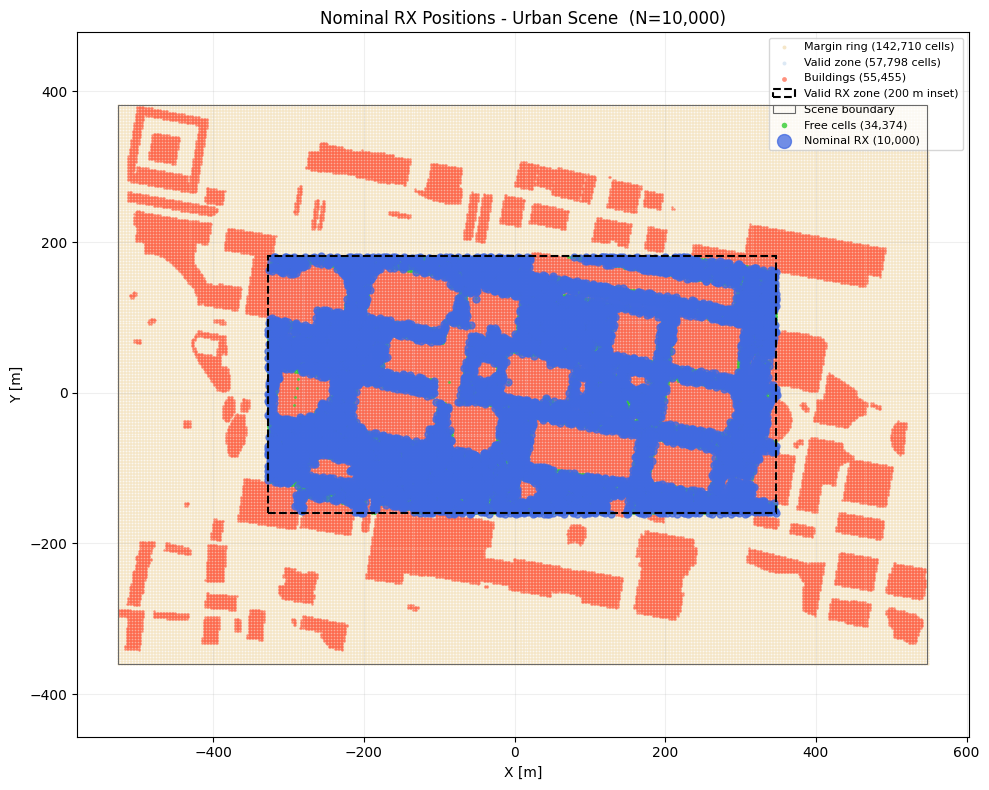

TX positions per elevation angle:
   90 deg  TX=(0.00 km, 0.00 km, 500.00 km)
   80 deg  TX=(0.00 km, 86.82 km, 492.40 km)
   70 deg  TX=(0.00 km, 171.01 km, 469.85 km)
   60 deg  TX=(0.00 km, 250.00 km, 433.01 km)
   50 deg  TX=(0.00 km, 321.39 km, 383.02 km)
   40 deg  TX=(0.00 km, 383.02 km, 321.39 km)
   30 deg  TX=(0.00 km, 433.01 km, 250.00 km)
   20 deg  TX=(0.00 km, 469.85 km, 171.01 km)
   10 deg  TX=(0.00 km, 492.40 km, 86.82 km)


In [8]:
# Visualise receiver placement
fig = plot_rx_positions(
    nominal_rx_positions = nominal_rx_positions,
    tx_pos               = None,
    free_xy              = free_xy,
    title                = f"Nominal RX Positions - Urban Scene  (N={len(nominal_rx_positions):,})",
    grid_meta=grid_meta
)
fig.savefig(f"{OUTPUT_DIR}/rx_positions_overview.png", dpi=120, bbox_inches='tight')
plt.show()
print("TX positions per elevation angle:")
for _elev in ELEVATION_ANGLES:
    _tp, _angles = tx_position_from_elevation(_elev, SLANT_DIST_M, SCENE_CENTER, radius=0, azimuth_deg=TX_AZIMUTH_DEG)
    print(f"  {_elev:3.0f} deg  TX=({_tp[0]/1e3:.2f} km, {_tp[1]/1e3:.2f} km, {_tp[2]/1e3:.2f} km)")

## 6 - Launch Simulations (Multi-GPU)

Two elevation angles are dispatched simultaneously, one per GPU, by
launching `run_elevation_sim.py` as subprocesses with different
`CUDA_VISIBLE_DEVICES` values.

```
GPU 0: elev=10  ──────────────────────► done
GPU 1: elev=30  ──────────────────────► done
                                              | wait for both
GPU 0: elev=60  ──────────────────────► done
GPU 1: elev=80  ──────────────────────► done
```

Set `NUM_GPUS = 1` in Section 3 to run all angles sequentially on GPU 0.

> **Non-blocking mode:** set `BLOCK_UNTIL_DONE = False` to start the
> subprocesses and continue editing. Call `wait_for_procs(active_procs)` later.

In [9]:
# ── Launch settings ─────────────────────────────────────────────────────────
# RESUME_FROM_CHECKPOINT: set this in the config cell above (cell 6).
# The launch cell reads it from the notebook namespace and passes it
# explicitly to each subprocess — no need to re-run the config cells.
BLOCK_UNTIL_DONE       = True  # False -> fire-and-forget
FORCE_FRESH_ANGLES     = []     # e.g. [10, 30] to force-restart specific angles
# RESUME_FROM_CHECKPOINT = False   # mirror of config-cell variable
os.makedirs(OUTPUT_DIR, exist_ok=True)
# Determine which angles still need to be run
angles_needed = []
for _angle in ELEVATION_ANGLES:
    _res_file = os.path.join(OUTPUT_DIR, f"results_elev{int(_angle):03d}deg.pkl")
    if os.path.exists(_res_file) and RESUME_FROM_CHECKPOINT and not (_angle in FORCE_FRESH_ANGLES):
        print(f"  elev={_angle} deg  -> already complete, skipping")
    else:
        angles_needed.append(_angle)
print(f"\nAngles to run: {angles_needed}")
def launch_angle(angle, gpu_id, resume, force_fresh=False):
    """Launch run_elevation_sim.py for one elevation angle.
    Args:
        resume      : value of RESUME_FROM_CHECKPOINT from the notebook
        force_fresh : if True, passes --no-resume regardless of `resume`
    The subprocess always receives an explicit --resume or --no-resume flag
    so the notebook variable is the authoritative source of truth.
    """
    _env = dict(os.environ)
    _env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
    _cmd = [
        sys.executable,
        os.path.join(SCRIPT_DIR, "run_elevation_sim.py"),
        "--elevation", str(angle),
        "--gpu_id",    str(gpu_id),
        "--config",    CONFIG_FILE,
        "--rx_file",   RX_POSITIONS_FILE,
        "--output",    OUTPUT_DIR,
    ]
    # Section 3.6: if a real/synthetic-orbit satellite source produced a
    # waypoints file, pass the matching waypoint index instead of relying
    # on --elevation alone (TX position AND velocity then come from the
    # real SGP4 pass sample -- see run_elevation_sim.py).
    _wp_file = globals().get("WAYPOINTS_FILE")
    if _wp_file:
        _wp_idx_map = globals().get("WAYPOINT_INDEX_BY_ANGLE", {})
        _wp_idx = _wp_idx_map.get(angle)
        if _wp_idx is None:
            raise KeyError(
                f"No waypoint index found for angle={angle} in "
                f"WAYPOINT_INDEX_BY_ANGLE -- did ELEVATION_ANGLES change after "
                f"Section 3.6 ran? Re-run Section 3.6 to regenerate it."
            )
        _cmd += ["--waypoints_file", _wp_file, "--waypoint_index", str(_wp_idx)]
    if force_fresh or not resume:
        _cmd.append("--no-resume")   # explicit fresh start
        if force_fresh:
            print(f"  [FORCE FRESH] elev={angle}° — checkpoint ignored (force_fresh)")
        else:
            print(f"  [FRESH START] elev={angle}° — checkpoint ignored (RESUME_FROM_CHECKPOINT=False)")
    else:
        _cmd.append("--resume")      # explicit resume
    _log = open(os.path.join(OUTPUT_DIR, f"log_elev{int(angle):03d}deg.txt"), "w")
    _p   = subprocess.Popen(_cmd, env=_env, stdout=_log, stderr=subprocess.STDOUT)
    print(f"  Launched PID {_p.pid}  elev={angle}°  GPU={gpu_id}  resume={resume and not force_fresh}")
    return _p
def wait_for_procs(procs, poll_interval=30):
    t0 = time.perf_counter()
    while True:
        still = [p for p in procs if p.poll() is None]
        if not still:
            break
        print(f"  [{time.strftime('%H:%M:%S')}]  {len(still)} still running  "
              f"({(time.perf_counter()-t0)/3600:.2f} h)")
        time.sleep(poll_interval)
    print(f"  All done.  Total: {(time.perf_counter()-t0)/3600:.2f} h")
# Dispatch
active_procs = []
if NUM_GPUS >= 2:
    _pairs = [angles_needed[i:i+2] for i in range(0, len(angles_needed), 2)]
    for _pair in _pairs:
        _pair_procs = []
        for _gpu_id, _angle in enumerate(_pair):
            _p = launch_angle(_angle, _gpu_id,
                              resume=RESUME_FROM_CHECKPOINT,
                              force_fresh=(_angle in FORCE_FRESH_ANGLES))
            _pair_procs.append(_p)
            active_procs.append(_p)
        if BLOCK_UNTIL_DONE:
            print(f"\nWaiting for pair {[a for a in _pair]}...")
            wait_for_procs(_pair_procs)
else:
    for _angle in angles_needed:
        _p = launch_angle(_angle, gpu_id=0,
                          resume=RESUME_FROM_CHECKPOINT,
                          force_fresh=(_angle in FORCE_FRESH_ANGLES))
        active_procs.append(_p)
        if BLOCK_UNTIL_DONE:
            wait_for_procs([_p])
if not BLOCK_UNTIL_DONE:
    print(f"\n{len(active_procs)} process(es) running in background.")
    print("Run: wait_for_procs(active_procs) to block until complete.")


Angles to run: [90, 80, 70, 60, 50, 40, 30, 20, 10]
  Launched PID 3727341  elev=90°  GPU=0  resume=True
  Launched PID 3727342  elev=80°  GPU=1  resume=True

Waiting for pair [90, 80]...
  [09:53:42]  2 still running  (0.00 h)
  [09:54:12]  2 still running  (0.01 h)
  [09:54:42]  2 still running  (0.02 h)
  [09:55:12]  2 still running  (0.03 h)
  [09:55:42]  2 still running  (0.03 h)
  [09:56:12]  2 still running  (0.04 h)
  [09:56:42]  2 still running  (0.05 h)
  [09:57:12]  2 still running  (0.06 h)
  [09:57:42]  2 still running  (0.07 h)
  [09:58:12]  2 still running  (0.08 h)
  [09:58:42]  2 still running  (0.08 h)
  [09:59:12]  2 still running  (0.09 h)
  [09:59:42]  2 still running  (0.10 h)
  [10:00:12]  2 still running  (0.11 h)
  [10:00:42]  2 still running  (0.12 h)
  [10:01:12]  2 still running  (0.13 h)
  [10:01:42]  2 still running  (0.13 h)
  [10:02:12]  2 still running  (0.14 h)
  [10:02:42]  2 still running  (0.15 h)
  [10:03:12]  2 still running  (0.16 h)
  [10:03:42

In [ ]:
# Optional manual wait + status check
# wait_for_procs(active_procs)
simulation_status(OUTPUT_DIR, ELEVATION_ANGLES)